<img src="../../../assets/images/logos/ucu_logo_clean.svg" alt="UCU Logo" width="200" style="float: right; margin: 0 0 10px 10px;"/>

### Matemáticas para Aprendizaje Automático - 2026

--------
## Laboratorio 3.3: Integración Numérica

#### Objetivos

- Implementar la regla del trapecio y la del punto medio, y verificar empíricamente que su error decae como $O(h^2)$.
- Extender la regla del punto medio a integrales dobles sobre rectángulos, y usar funciones indicadoras para calcular áreas de regiones arbitrarias.
- Implementar el método de Monte Carlo para estimar integrales, áreas y volúmenes, y medir su orden de convergencia $O(N^{-1/2})$.
- Comparar la precisión y el costo de los métodos deterministas y de Monte Carlo, y explicar por qué Monte Carlo es el que escala a alta dimensión.

## Introducción

Muchas cantidades del aprendizaje automático son integrales: la pérdida esperada de un modelo es una integral sobre la distribución de los datos, el área bajo la curva ROC se calcula con la regla del trapecio, y las constantes de normalización de los modelos probabilísticos son integrales en muchas dimensiones. Casi ninguna de ellas tiene una primitiva cerrada, así que se aproximan numéricamente. Elegir el método adecuado depende de dos preguntas: qué tan rápido baja el error al invertir más cómputo, y qué pasa con ese costo cuando crece la dimensión.

En la Parte 1 vas a implementar las reglas del trapecio y del punto medio y a medir su orden de convergencia. En la Parte 2 vas a extender el punto medio a dos dimensiones y a calcular áreas con funciones indicadoras. En la Parte 3 vas a implementar el método de Monte Carlo y a compararlo con los métodos deterministas. Cada implementación se valida contra integrales con valor exacto conocido y contra el orden de convergencia que predice la teoría.

In [10]:
# Librerías necesarias
import numpy as np
import matplotlib.pyplot as plt


def pendiente_loglog(x, y):
    """
    Estima el exponente p del modelo y = C x^p ajustando una recta por mínimos
    cuadrados a los datos en escala logarítmica: log y = log C + p log x.

    Esta función viene dada. Se usa en todo el laboratorio como test numérico del
    orden de convergencia: si el error decae como O(n^-2), la pendiente ajustada
    del error frente a n es cercana a -2.
    """
    p, _ = np.polyfit(np.log(np.asarray(x, dtype=float)),
                      np.log(np.asarray(y, dtype=float)), 1)
    return p

## Parte 1: Sumas de Riemann

La integral definida de una función $f$ en el intervalo $[a, b]$ es el límite de las sumas de Riemann:

$$\int_a^b f(x)\, dx = \lim_{n \to \infty} \sum_{i=0}^{n-1} f(x^*_i)\, \Delta x_i,$$

donde $a = x_0 < x_1 < \cdots < x_n = b$ es una partición de $[a, b]$ en $n$ subintervalos, $\Delta x_i = x_{i+1} - x_i$ es el ancho de cada uno y $x^*_i$ es un punto del subintervalo $[x_i, x_{i+1}]$. Para evaluarla numéricamente hay que tomar dos decisiones:

1. Usar una cantidad **finita** de subintervalos $n$, que controla la precisión: $\int_a^b f(x)\, dx \approx \sum_{i=0}^{n-1} f(x^*_i)\, \Delta x_i$.
2. Elegir la **partición** y los puntos $x^*_i$, que determinan la forma de la aproximación.

En este laboratorio usamos intervalos uniformes, $x_i = a + i h$ con $h = \frac{b - a}{n}$. Con todos los anchos iguales, los puntos $x^*_i$ se pueden elegir de varias maneras:

- **Extremo izquierdo**: $x^*_i = x_i$.
- **Extremo derecho**: $x^*_i = x_{i+1}$.
- **Punto medio**: $x^*_i = \frac{x_i + x_{i+1}}{2}$.
- **Punto aleatorio**: $x^*_i$ es un punto aleatorio de $[x_i, x_{i+1}]$.
- **Punto de valor medio**: $x^*_i$ tal que $f(x^*_i) = \frac{f(x_i) + f(x_{i+1})}{2}$.

Nos vamos a concentrar en el punto medio y en el punto de valor medio. Este último da lugar a la **regla del trapecio**, porque aproxima la integral por la suma de las áreas de los trapecios de vértices $(x_i, 0)$, $(x_i, f(x_i))$, $(x_{i+1}, f(x_{i+1}))$ y $(x_{i+1}, 0)$.

**Regla del punto medio**:

$$M_n = h \sum_{i=0}^{n-1} f\!\left(\frac{x_i + x_{i+1}}{2}\right).$$

**Regla del trapecio**:

$$T_n = \frac{h}{2}\big[f(a) + 2 f(x_1) + 2 f(x_2) + \cdots + 2 f(x_{n-1}) + f(b)\big].$$

**Error.** Si $f$ tiene derivada segunda continua, existen puntos $\xi, \eta \in [a, b]$ tales que

$$T_n - \int_a^b f(x)\, dx = \frac{(b - a)\, h^2}{12}\, f''(\xi), \qquad M_n - \int_a^b f(x)\, dx = -\frac{(b - a)\, h^2}{24}\, f''(\eta).$$

Ambas reglas tienen error $O(h^2) = O(n^{-2})$: duplicar $n$ divide el error por cuatro. Además, el error del punto medio es aproximadamente la mitad del error del trapecio y tiene el signo opuesto. En esta parte vas a implementar las dos reglas y a verificar estas tres afirmaciones.

### Ejercicio L3.3.1: Regla del Trapecio y Punto Medio

Implementá las dos reglas de la introducción para aproximar $\int_a^b f(x)\, dx$ con $n$ subintervalos.

**a)** `regla_trapecio(f, a, b, n)`: devuelve $T_n$.

**b)** `regla_punto_medio(f, a, b, n)`: devuelve $M_n$.

**c)** Probá ambas reglas con $n = 10$ subintervalos sobre:
- $f(x) = x^2$ en $[0, 1]$. Valor exacto: $1/3$.
- $f(x) = \sin(x)$ en $[0, \pi/2]$. Valor exacto: $1$.

**Nota:** `np.linspace(a, b, n + 1)` devuelve los $n + 1$ puntos de la partición. Las funciones `f` reciben arrays, así que no hace falta ningún bucle.

In [11]:
def regla_trapecio(f, a, b, n):
    """
    Aproxima la integral de f en [a, b] con la regla del trapecio.

    Args:
        f: función que se evalúa sobre arrays
        a, b: extremos del intervalo
        n: número de subintervalos

    Returns:
        resultado: aproximación T_n de la integral (escalar)
    """
    h = (b-a)/n #ancho de los subintervalos
    x = np.linspace(a,b,n+1)
    y=f(x)
    resultado =h/2*(y[0]+ 2*np.sum(y[1:-1])+y[-1])
    return resultado


def regla_punto_medio(f, a, b, n):
    """
    Aproxima la integral de f en [a, b] con la regla del punto medio.

    Args:
        f: función que se evalúa sobre arrays
        a, b: extremos del intervalo
        n: número de subintervalos

    Returns:
        resultado: aproximación M_n de la integral (escalar)
    """
    h = (b - a) / n
    x_mid = np.linspace(a + h/2, b - h/2, n)   # n puntos medios
    resultado =h*np.sum(f(x_mid))
    return resultado


def f_test(x):
    return x**2


def f_test2(x):
    return np.sin(x)


# c) f(x) = x^2 en [0, 1] y f(x) = sin(x) en [0, pi/2], con n = 10 subintervalos
aprox_trap_x2 = regla_trapecio(f_test, 0, 1, 10)
aprox_mid_x2 = regla_punto_medio(f_test, 0, 1, 10)
aprox_trap_sin = regla_trapecio(f_test2, 0, np.pi / 2, 10)
aprox_mid_sin = regla_punto_medio(f_test2, 0, np.pi / 2, 10)

# ── Verificación ─────────────────────────────────────────────────────────────
# Caso analítico: para f(x) = x^2, f'' = 2 es constante y los términos de error son exactos,
#   T_10 = 1/3 + (1)(0.1)^2 (2) / 12 = 1/3 + 1/600,    M_10 = 1/3 - (1)(0.1)^2 (2) / 24 = 1/3 - 1/1200.
assert np.isclose(aprox_trap_x2, 1 / 3 + 1 / 600), "El trapecio sobre x^2 no coincide con el valor analítico 1/3 + 1/600"
assert np.isclose(aprox_mid_x2, 1 / 3 - 1 / 1200), "El punto medio sobre x^2 no coincide con el valor analítico 1/3 - 1/1200"
# sin es cóncava en [0, pi/2] (f'' < 0): el trapecio subestima y el punto medio sobreestima.
assert aprox_trap_sin < 1.0 < aprox_mid_sin, "En una función cóncava el trapecio subestima y el punto medio sobreestima"
assert np.isclose(abs(aprox_trap_sin - 1), 2 * abs(aprox_mid_sin - 1), rtol=1e-2), \
    "El error del trapecio debe ser aproximadamente el doble del error del punto medio"
print(f"Obtenido : x^2 -> trapecio = {aprox_trap_x2:.8f} | punto medio = {aprox_mid_x2:.8f}")
print(f"Esperado : x^2 -> trapecio = {1 / 3 + 1 / 600:.8f} | punto medio = {1 / 3 - 1 / 1200:.8f}")
print(f"sin      : trapecio = {aprox_trap_sin:.8f} | punto medio = {aprox_mid_sin:.8f} | exacto = 1")

Obtenido : x^2 -> trapecio = 0.33500000 | punto medio = 0.33250000
Esperado : x^2 -> trapecio = 0.33500000 | punto medio = 0.33250000
sin      : trapecio = 0.99794299 | punto medio = 1.00102882 | exacto = 1


### Ejercicio L3.3.2: Convergencia y Orden del Error

Estudiá cómo decae el error de las dos reglas al aumentar el número de subintervalos.

**a)** Elegí un conjunto de valores de $n$ entre $1$ y $1000$ (al menos $20$ valores) y calculá el error absoluto de cada regla para $f(x) = x^2$ en $[0, 1]$ y para $f(x) = \sin(x)$ en $[0, \pi/2]$.

**b)** Estimá el orden de convergencia de cada caso con `pendiente_loglog(n_values, errores)`.

**c)** Graficá los cuatro errores frente a $n$ en escala log-log, un panel por función.

**Nota:** valores de $n$ espaciados logarítmicamente (`np.logspace(0, 3, 50).astype(int)`, quitando repetidos con `np.unique`) se ven mejor en escala log-log que un `range`. En escala log-log, un error $C n^{p}$ es una recta de pendiente $p$.

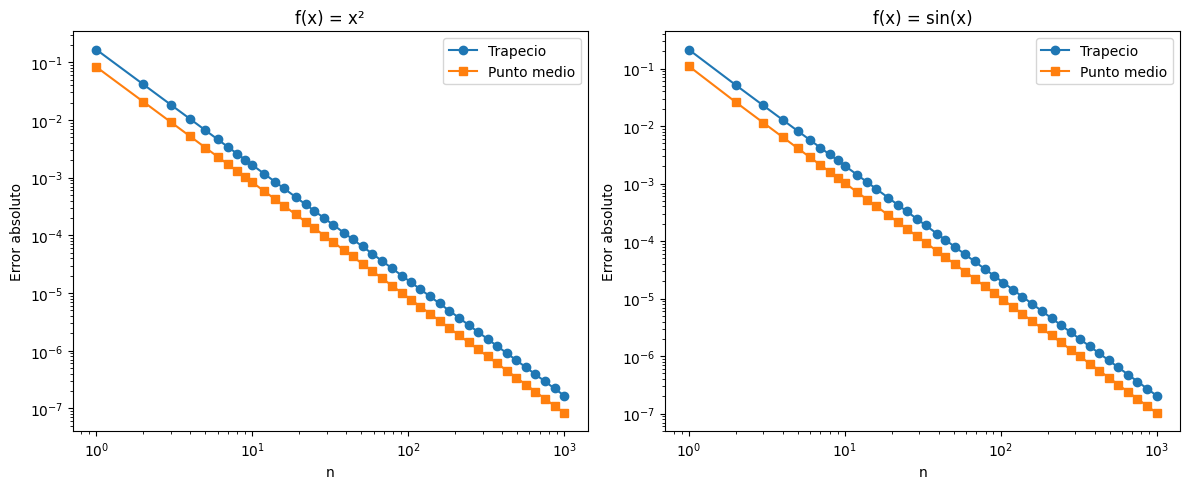

Obtenido : pendientes x^2 -> trapecio = -2.000 | punto medio = -2.000
           pendientes sin -> trapecio = -2.002 | punto medio = -2.003
Esperado : -2 en los cuatro casos


In [12]:
# a) Valores de n y errores
n_values =np.unique(np.logspace(0, 3, 50).astype(int))   # ~40 enteros entre 1 y 1000


exacto_x2 = 1 / 3
exacto_sin = 1.0
errores_trap_x2  = np.array([abs(regla_trapecio(lambda x: x**2, 0, 1, n) - exacto_x2) for n in n_values])
errores_mid_x2   = np.array([abs(regla_punto_medio(lambda x: x**2, 0, 1, n) - exacto_x2) for n in n_values])
errores_trap_sin = np.array([abs(regla_trapecio(np.sin, 0, np.pi/2, n) - exacto_sin) for n in n_values])
errores_mid_sin  = np.array([abs(regla_punto_medio(np.sin, 0, np.pi/2, n) - exacto_sin) for n in n_values])

# b) Orden de convergencia
p_trap_x2  = pendiente_loglog(n_values, errores_trap_x2)
p_mid_x2   = pendiente_loglog(n_values, errores_mid_x2)
p_trap_sin = pendiente_loglog(n_values, errores_trap_sin)
p_mid_sin  = pendiente_loglog(n_values, errores_mid_sin)

# c) Gráfico log-log
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].loglog(n_values, errores_trap_x2, "o-", label="Trapecio")
axes[0].loglog(n_values, errores_mid_x2, "s-", label="Punto medio")
axes[0].set_title("f(x) = x²"); axes[0].set_xlabel("n"); axes[0].set_ylabel("Error absoluto"); axes[0].legend()

axes[1].loglog(n_values, errores_trap_sin, "o-", label="Trapecio")
axes[1].loglog(n_values, errores_mid_sin, "s-", label="Punto medio")
axes[1].set_title("f(x) = sin(x)"); axes[1].set_xlabel("n"); axes[1].set_ylabel("Error absoluto"); axes[1].legend()
plt.tight_layout()
plt.show()

# ── Verificación ─────────────────────────────────────────────────────────────
assert len(n_values) >= 20 and min(n_values) >= 1 and max(n_values) <= 1000, \
    "Usá al menos 20 valores de n entre 1 y 1000"
assert len(errores_trap_x2) == len(n_values) and len(errores_mid_sin) == len(n_values), \
    "Debe haber un error por cada valor de n"
for nombre, p in [("trapecio, x^2", p_trap_x2), ("punto medio, x^2", p_mid_x2),
                  ("trapecio, sin", p_trap_sin), ("punto medio, sin", p_mid_sin)]:
    assert abs(p + 2) < 0.1, f"El orden de convergencia ({nombre}) debe ser cercano a -2, es decir O(n^-2)"
print(f"Obtenido : pendientes x^2 -> trapecio = {p_trap_x2:.3f} | punto medio = {p_mid_x2:.3f}")
print(f"           pendientes sin -> trapecio = {p_trap_sin:.3f} | punto medio = {p_mid_sin:.3f}")
print("Esperado : -2 en los cuatro casos")

## Parte 2: Integración Bidimensional

Sea $R = [x_{\min}, x_{\max}] \times [y_{\min}, y_{\max}]$ un rectángulo y $f: R \to \mathbb{R}$ continua. Por el **teorema de Fubini**, la integral doble se calcula como dos integrales iteradas:

$$\iint_R f(x, y)\, dA = \int_{x_{\min}}^{x_{\max}} \left( \int_{y_{\min}}^{y_{\max}} f(x, y)\, dy \right) dx.$$

Aplicando la regla del punto medio en cada integral, con $n_x$ subintervalos de ancho $h_x$ en $x$ y $n_y$ de ancho $h_y$ en $y$, se obtiene la **regla del punto medio en 2D**:

$$\iint_R f(x, y)\, dA \approx h_x h_y \sum_{i=0}^{n_x - 1} \sum_{j=0}^{n_y - 1} f(x^*_i,\, y^*_j),$$

donde $x^*_i$ e $y^*_j$ son los puntos medios de cada subintervalo. Geométricamente, se aproxima el volumen bajo la superficie por $n_x n_y$ prismas de base $h_x \times h_y$. Para funciones suaves el error sigue siendo $O(h^2)$, igual que en 1D.

**Regiones arbitrarias.** Para integrar sobre una región $D$ que no es un rectángulo, se la encierra en un rectángulo $R \supseteq D$ y se integra la **función indicadora**

$$\mathbb{1}_D(x, y) = \begin{cases} 1 & \text{si } (x, y) \in D, \\ 0 & \text{si no,} \end{cases} \qquad \text{Área}(D) = \iint_R \mathbb{1}_D(x, y)\, dA.$$

La indicadora es discontinua en el borde de $D$, así que la cota de error $O(h^2)$ deja de valer: la convergencia depende de cómo corta la grilla al borde, y es más lenta e irregular.

**Costo.** La regla en 2D evalúa $f$ en $n_x n_y$ puntos. En $d$ dimensiones, con $n$ puntos por eje, harían falta $n^d$ evaluaciones: con $n = 100$ y $d = 10$ son $10^{20}$. Este crecimiento exponencial, conocido como la **maldición de la dimensionalidad**, es lo que motiva el método de la Parte 3.

### Ejercicio L3.3.3: Integración Numérica en 2D sobre Rectángulos

**a)** Implementá `integracion_2d(f, x_min, x_max, y_min, y_max, nx, ny)` con la regla del punto medio en 2D.

**b)** Implementá $f(x, y) = (x y)^2$ y aproximá su integral sobre $[0, 1] \times [0, 1]$ con $n_x = n_y = 4$, $10$ y $100$. Valor exacto: $1/9$.

El bloque de verificación agrega por su cuenta dos controles: el valor exacto de la regla sobre esta función separable, y una integral con $n_x \neq n_y$ sobre un rectángulo no cuadrado, para detectar ejes intercambiados.

**Nota:** `X, Y = np.meshgrid(x_mid, y_mid)` arma la grilla de puntos medios, y `f(X, Y)` evalúa $f$ en todos ellos a la vez.

In [13]:
def integracion_2d(f, x_min, x_max, y_min, y_max, nx, ny):
    """
    Aproxima la integral doble de f sobre [x_min, x_max] x [y_min, y_max]
    con la regla del punto medio en 2D.

    Args:
        f: función f(x, y) que se evalúa sobre arrays
        x_min, x_max, y_min, y_max: extremos del rectángulo
        nx, ny: número de subintervalos en x y en y

    Returns:
        total: aproximación de la integral (escalar)
    """
    hx = (x_max-x_min)/nx  #ancho de cada subintervalo en x
    hy = (y_max-y_min)/ny  #ancho de cada subintervalo en y
    x_mid = np.linspace(x_min+hx/2,x_max-hx/2,nx)  #nx puntos medios en x
    y_mid = np.linspace(y_min+hy/2,y_max-hy/2,ny)  #ny puntos medios en y
    total = hx*hy*np.sum(f(*np.meshgrid(x_mid, y_mid))) #puntos medios, evalúa f, suma y multiplica por el área de cada celda
    return total


def f_2d(x, y):
    """f(x, y) = (x y)^2."""
    return (x * y)**2


exacto_2d = 1 / 9
ns_2d = [4, 10, 100]
errores_2d = []
for n in ns_2d:
    aprox = integracion_2d(f_2d, 0, 1, 0, 1, n, n)
    errores_2d.append(abs(aprox - exacto_2d))
    print(f"n = {n:3d} | aprox = {aprox:.8f} | error = {errores_2d[-1]:.2e}")

# ── Verificación ─────────────────────────────────────────────────────────────
# Caso analítico: (x y)^2 es separable, así que la regla 2D es el producto de dos reglas 1D
# sobre x^2, cada una igual a 1/3 - 1/(12 n^2).
for n in ns_2d:
    assert np.isclose(integracion_2d(f_2d, 0, 1, 0, 1, n, n), (1 / 3 - 1 / (12 * n**2))**2), \
        f"Con n = {n}, la regla 2D sobre (xy)^2 debe valer (1/3 - 1/(12 n^2))^2"
# f(x, y) = x sobre [0, 2] x [0, 1]: la integral exacta es 2, y el punto medio integra exactamente las funciones lineales.
assert np.isclose(integracion_2d(lambda x, y: x + 0 * y, 0, 2, 0, 1, 3, 5), 2.0), \
    "Con nx != ny en un rectángulo no cuadrado el resultado es incorrecto: revisá qué puntos medios van en cada eje"
assert abs(pendiente_loglog(ns_2d, errores_2d) + 2) < 0.1, "El error de la regla 2D debe decaer como O(n^-2)"
print("Obtenido : errores =", [f"{e:.2e}" for e in errores_2d])
print("Esperado : errores =", [f"{abs((1 / 3 - 1 / (12 * n**2))**2 - exacto_2d):.2e}" for n in ns_2d])

n =   4 | aprox = 0.10766602 | error = 3.45e-03
n =  10 | aprox = 0.11055625 | error = 5.55e-04
n = 100 | aprox = 0.11110556 | error = 5.56e-06
Obtenido : errores = ['3.45e-03', '5.55e-04', '5.56e-06']
Esperado : errores = ['3.45e-03', '5.55e-04', '5.56e-06']


### Ejercicio L3.3.4: Área de una Región Arbitraria

Usá la regla del punto medio en 2D con funciones indicadoras para calcular el área de dos regiones.

**a)** Implementá `circulo_unitario(x, y)`, la indicadora del círculo $x^2 + y^2 \leq 1$, y calculá su área sobre el rectángulo contenedor $[-1, 1] \times [-1, 1]$. Valor exacto: $\pi$.

**b)** Implementá `elipse(x, y)`, la indicadora de la elipse $x^2 + \frac{y^2}{4} \leq 1$ (semiejes $a = 1$ y $b = 2$), y calculá su área sobre $[-1, 1] \times [-2, 2]$. Escribí también el área exacta, $\pi a b$.

**Nota:** una comparación sobre arrays, como `x**2 + y**2 <= 1`, devuelve un array booleano. Con `.astype(float)` se convierte en ceros y unos.

In [14]:
def circulo_unitario(x, y):
    """Indicadora del círculo unitario: 1 si x^2 + y^2 <= 1, 0 si no."""
    return (x**2+y**2<=1).astype(float) #1 si el punto cae dentro del círculo, 0 si no


def elipse(x, y):
    """Indicadora de la elipse x^2 + y^2/4 <= 1: 1 si el punto está dentro, 0 si no."""
    return  (x**2+y**2/4<=1).astype(float) #1 si el punto cae dentro de la elipse, 0 si no


nx, ny = 100, 100

# a) Área del círculo unitario
area_circulo = integracion_2d(circulo_unitario, -1, 1, -1, 1, nx, ny)
print(f"Área del círculo unitario: {area_circulo:.6f} | error respecto de pi: {abs(area_circulo - np.pi):.6f}")

# b) Área de la elipse
area_elipse = integracion_2d(elipse, -1, 1, -2, 2, nx, ny)
area_exacta_elipse =np.pi*1*2
print(f"Área de la elipse:         {area_elipse:.6f} | error respecto del exacto: {abs(area_elipse - area_exacta_elipse):.6f}")

# ── Verificación ─────────────────────────────────────────────────────────────
assert np.allclose(circulo_unitario(np.array([0.0, 1.0, 0.8]), np.array([0.0, 0.0, 0.8])), [1, 1, 0]), \
    "La indicadora del círculo debe valer 1 adentro y en el borde, y 0 afuera"
assert np.allclose(elipse(np.array([0.0, 0.0, 1.0]), np.array([0.0, 2.0, 1.0])), [1, 1, 0]), \
    "La indicadora de la elipse debe valer 1 adentro y en el borde, y 0 afuera"
assert np.isclose(area_exacta_elipse, 2 * np.pi), "El área de la elipse de semiejes 1 y 2 es 2 pi"
assert abs(area_circulo - np.pi) < 5e-3, "El área del círculo debe aproximar pi"
assert abs(area_elipse - area_exacta_elipse) < 1e-2, "El área de la elipse debe aproximar 2 pi"
print(f"Obtenido : círculo = {area_circulo:.6f} | elipse = {area_elipse:.6f}")
print(f"Esperado : círculo = {np.pi:.6f} | elipse = {2 * np.pi:.6f}")

Área del círculo unitario: 3.144000 | error respecto de pi: 0.002407
Área de la elipse:         6.288000 | error respecto del exacto: 0.004815
Obtenido : círculo = 3.144000 | elipse = 6.288000
Esperado : círculo = 3.141593 | elipse = 6.283185


## Parte 3: Método de Monte Carlo

Se llama **método de Monte Carlo** a las técnicas que usan números aleatorios para estimar cantidades que en principio son deterministas. Aplicado a integrales, se basa en ver la integral como un **valor medio**. Si $|R|$ es el volumen (o la longitud, o el área) de una región $R \subseteq \mathbb{R}^d$, el valor medio de $f$ en $R$ es

$$\mu = \frac{1}{|R|} \int_R f(x)\, dx \qquad \Longrightarrow \qquad \int_R f(x)\, dx = |R|\, \mu.$$

Tomando $N$ puntos $x_1, \dots, x_N$ uniformes e independientes en $R$, el promedio de $f$ en esos puntos estima $\mu$:

$$\int_R f(x)\, dx \approx |R| \cdot \frac{1}{N} \sum_{i=1}^{N} f(x_i).$$

**Áreas y volúmenes.** Con $f = \mathbb{1}_D$, la indicadora de una región $D \subseteq R$, el promedio es la fracción de puntos que caen dentro de $D$:

$$\text{Área}(D) \approx |R| \cdot \frac{\#\{\text{puntos dentro de } D\}}{N}.$$

**Error.** El estimador es aleatorio, y su desvío estándar es $|R|\, \sigma_f / \sqrt{N}$, donde $\sigma_f$ es el desvío de $f$ en $R$. El error decae entonces como $O(N^{-1/2})$: para ganar un dígito de precisión hay que multiplicar $N$ por cien. Es mucho más lento que el $O(n^{-2})$ de la Parte 1, pero tiene una propiedad que ningún método de grilla tiene: **no depende de la dimensión** $d$. Por eso Monte Carlo es el método estándar para integrar en muchas dimensiones.

Los ejercicios fijan la semilla del generador aleatorio para que los resultados sean reproducibles.

### Ejercicio L3.3.5: Integración mediante Puntos Aleatorios

**a)** Implementá `monte_carlo_integral(f, a, b, n_puntos)`, que estima $\int_a^b f(x)\, dx$ como $(b - a)$ por el promedio de $f$ en `n_puntos` puntos uniformes en $[a, b]$.

**b)** Estimá $\int_0^1 x^2\, dx$ con $10$, $100$, $1000$ y $10000$ puntos, y compará el error con el de la regla del trapecio con el mismo número de subintervalos. El andamiaje grafica ambos errores.

El bloque de verificación agrega por su cuenta una estimación del orden de convergencia de Monte Carlo, promediando el error de $30$ repeticiones para cada $N$.

**Nota:** `np.random.uniform(a, b, n)` genera `n` puntos uniformes en $[a, b]$.

n =     10 | Monte Carlo: 0.328551 | Trapecio: 0.3350000000
n =    100 | Monte Carlo: 0.344432 | Trapecio: 0.3333500000
n =   1000 | Monte Carlo: 0.326762 | Trapecio: 0.3333335000
n =  10000 | Monte Carlo: 0.336563 | Trapecio: 0.3333333350


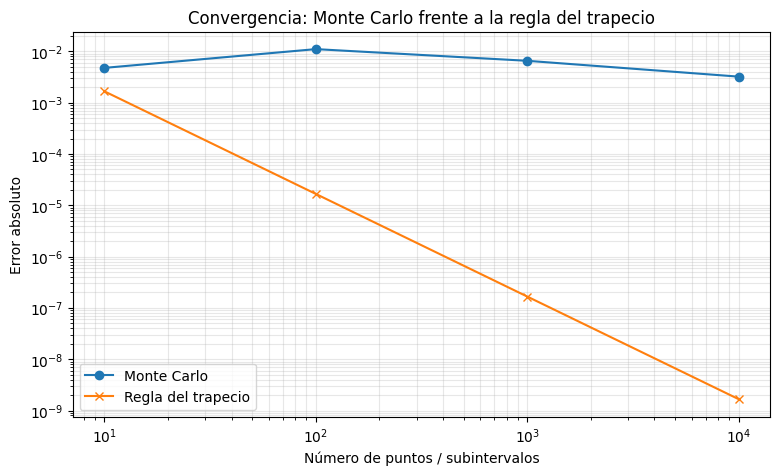

Obtenido : pendiente de Monte Carlo = -0.510
Esperado : -0.5


In [15]:
np.random.seed(5)


def monte_carlo_integral(f, a, b, n_puntos):
    """
    Estima la integral de f en [a, b] por Monte Carlo.

    Args:
        f: función que se evalúa sobre arrays
        a, b: extremos del intervalo
        n_puntos: número de puntos aleatorios

    Returns:
        estimacion: estimación de la integral (escalar)
    """
    puntos =np.random.uniform(a,b,n_puntos) #n_puntos x uniformes en [a,b]
    estimacion =(b-a)*np.mean(f(puntos)) #largo del intervalo × promedio de f
    return estimacion


# b) Monte Carlo frente a la regla del trapecio para x^2 en [0, 1]
valor_exacto = 1 / 3
n_puntos_list = [10, 100, 1000, 10000]

mc_errors = []
trap_errors = []
for n in n_puntos_list:
    mc_est = monte_carlo_integral(f_test, 0, 1, n)
    trap_est = regla_trapecio(f_test, 0, 1, n)
    mc_errors.append(abs(mc_est - valor_exacto))
    trap_errors.append(abs(trap_est - valor_exacto))
    print(f"n = {n:6d} | Monte Carlo: {mc_est:.6f} | Trapecio: {trap_est:.10f}")

plt.figure(figsize=(9, 5))
plt.loglog(n_puntos_list, mc_errors, label="Monte Carlo", marker="o")
plt.loglog(n_puntos_list, trap_errors, label="Regla del trapecio", marker="x")
plt.xlabel("Número de puntos / subintervalos")
plt.ylabel("Error absoluto")
plt.title("Convergencia: Monte Carlo frente a la regla del trapecio")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

# ── Verificación ─────────────────────────────────────────────────────────────
np.random.seed(55)
Ns = [100, 1000, 10000, 100000]
err_medio = [np.mean([abs(monte_carlo_integral(f_test, 0, 1, N) - valor_exacto) for _ in range(30)]) for N in Ns]
p_mc = pendiente_loglog(Ns, err_medio)

assert mc_errors[-1] < 0.02, "Con 10000 puntos, el error de Monte Carlo debe ser menor que 0.02"
assert trap_errors[-1] < 1e-8, "Con 10000 subintervalos, el error del trapecio sobre x^2 es 1/(6 n^2), menor que 1e-8"
assert trap_errors[-1] < mc_errors[-1], "En 1D, la regla del trapecio debe ser mucho más precisa que Monte Carlo"
assert abs(p_mc + 0.5) < 0.2, "El error medio de Monte Carlo debe decaer como O(N^-1/2)"
print(f"Obtenido : pendiente de Monte Carlo = {p_mc:.3f}")
print("Esperado : -0.5")

### Ejercicio L3.3.6: Área de un Círculo y Volumen de una Esfera

Combiná Monte Carlo con funciones indicadoras para estimar:

**a)** El **área del círculo unitario**, con puntos uniformes en el cuadrado $[-1, 1]^2$, de área $4$. Valor exacto: $\pi$.

**b)** El **volumen de la esfera unitaria**, con puntos uniformes en el cubo $[-1, 1]^3$, de volumen $8$. Valor exacto: $\frac{4}{3}\pi$.

Compará las estimaciones con los valores exactos para $N = 1000$, $10000$ y $100000$.

**Nota:** pasar de 2D a 3D sólo agrega una coordenada aleatoria más; con una grilla de $100$ puntos por eje habría que pasar de $10^4$ a $10^6$ evaluaciones.

In [16]:
np.random.seed(6)


def monte_carlo_area_circulo(n_puntos):
    """
    Estima el área del círculo unitario por Monte Carlo, dentro del cuadrado [-1, 1]^2 de área 4.

    Returns:
        estimación del área (escalar)
    """
    x = np.random.uniform(-1,1,n_puntos)   #coordenadas x al azar
    y = np.random.uniform(-1,1,n_puntos)   #coordenadas y al azar
    dentro = x**2+y**2 <= 1   #True si el punto cae en el círculo
    return 4 * np.mean(dentro)  #área del cuadrado × fracción adentro


def monte_carlo_volumen_esfera(n_puntos):
    """
    Estima el volumen de la esfera unitaria por Monte Carlo, dentro del cubo [-1, 1]^3 de volumen 8.

    Returns:
        estimación del volumen (escalar)
    """
    x = np.random.uniform(-1,1,n_puntos)        
    y = np.random.uniform(-1,1,n_puntos)       
    z = np.random.uniform(-1,1,n_puntos)        
    dentro = x**2+y**2+z**2<= 1             
    return 8 * np.mean(dentro)                  

area_exacta_circulo =np.pi
vol_exacto_esfera = 4 / 3 * np.pi

resultados = []
for n in [1000, 10000, 100000]:
    area_mc = monte_carlo_area_circulo(n)
    vol_mc = monte_carlo_volumen_esfera(n)
    resultados.append((n, area_mc, vol_mc))
    print(f"N = {n:7d} | Área círculo: {area_mc:.5f} (error = {abs(area_mc - area_exacta_circulo):.5f}) | "
          f"Volumen esfera: {vol_mc:.5f} (error = {abs(vol_mc - vol_exacto_esfera):.5f})")

# ── Verificación ─────────────────────────────────────────────────────────────
_, area_final, vol_final = resultados[-1]

assert np.isclose(area_exacta_circulo, np.pi) and np.isclose(vol_exacto_esfera, 4 * np.pi / 3), \
    "Los valores exactos son pi y 4 pi / 3"
assert all(0 <= a <= 4 and 0 <= v <= 8 for _, a, v in resultados), \
    "Las estimaciones no pueden superar el área del cuadrado ni el volumen del cubo"
assert abs(area_final - np.pi) < 0.03, "Con N = 100000, el área estimada debe estar a menos de 0.03 de pi"
assert abs(vol_final - 4 * np.pi / 3) < 0.06, "Con N = 100000, el volumen estimado debe estar a menos de 0.06 de 4 pi / 3"
print(f"Obtenido : área = {area_final:.5f} | volumen = {vol_final:.5f}")
print(f"Esperado : área = {np.pi:.5f} | volumen = {4 * np.pi / 3:.5f}")

N =    1000 | Área círculo: 3.14400 (error = 0.00241) | Volumen esfera: 3.96800 (error = 0.22079)
N =   10000 | Área círculo: 3.16520 (error = 0.02361) | Volumen esfera: 4.12560 (error = 0.06319)
N =  100000 | Área círculo: 3.14736 (error = 0.00577) | Volumen esfera: 4.18824 (error = 0.00055)
Obtenido : área = 3.14736 | volumen = 4.18824
Esperado : área = 3.14159 | volumen = 4.18879


## Conclusiones

En este laboratorio hemos explorado:

1. **Reglas del trapecio y del punto medio**: ambas tienen error $O(h^2)$, con constantes conocidas ($f''/12$ y $-f''/24$) que para $f(x) = x^2$ predicen el resultado exacto de la regla. La pendiente $-2$ en escala log-log lo confirma, y el error del punto medio resulta la mitad del del trapecio y de signo opuesto.
2. **Integración bidimensional**: el teorema de Fubini convierte la integral doble en dos integrales iteradas, y la regla del punto medio en 2D conserva el orden $O(h^2)$ para funciones suaves. Con funciones indicadoras se calculan áreas de regiones arbitrarias, pero la discontinuidad en el borde vuelve la convergencia más lenta. El costo crece como $n^d$ con la dimensión.
3. **Método de Monte Carlo**: ver la integral como un valor medio y estimarlo con puntos aleatorios da un error $O(N^{-1/2})$, verificado con una pendiente cercana a $-1/2$. Es un orden mucho peor que el de las reglas deterministas, pero no depende de la dimensión.
4. **Comparación de métodos**: en una dimensión, con $10^4$ evaluaciones, el trapecio tiene un error del orden de $10^{-9}$ y Monte Carlo del orden de $10^{-3}$. En muchas dimensiones la relación se invierte, porque una grilla necesita $n^d$ puntos y Monte Carlo sigue necesitando $N$. Por eso las esperanzas en alta dimensión que aparecen en aprendizaje automático se estiman por muestreo.

## Declaración de uso de inteligencia artificial

> **Política del curso (syllabus).** Se permite usar herramientas de IA (ChatGPT, Copilot, Claude, etc.)
> *como apoyo para el aprendizaje*: entender conceptos, explorar ideas, depurar código o buscar
> explicaciones alternativas. **No** se permite usarlas para **resolver los ejercicios evaluados** ni
> para **verificar las respuestas antes de entregar**. Se espera que cada estudiante resuelva todos los
> problemas por sí mismo/a.

Completá esta declaración **escribiendo tu respuesta** donde aparece «…» (doble clic en esta celda para
editarla y luego Ctrl/Cmd + Enter para volver a renderizarla):

**1. ¿Usaste herramientas de IA en este laboratorio?** (Sí / No): Si

**2. ¿Cuál(es)?** (ChatGPT, Copilot, Claude, …; escribí "ninguna" si no usaste): Claude

**3. ¿Para qué la(s) usaste?** Usos permitidos: entender conceptos, explorar ideas, depurar código,
buscar explicaciones alternativas. Escribí los que apliquen: para entender los conceptos, ejemplos similares 

**4. Detalle breve:** «En qué ejercicios y de qué manera. En casi todos pidiendo explicaciones alternativas aplicadas, y en la parte de graficar 

**Declaración de honestidad académica.** Declaro que resolví los ejercicios de este laboratorio por mí
mismo/a y que no utilicé herramientas de IA para resolver los ejercicios evaluados ni para verificar mis
respuestas antes de entregar, de acuerdo con la política del curso.

**Nombre y apellido:** Domingo Leiva          **Fecha:** 28/11/2026